# Axis 2 — Eviction Policy & Expert Locality (Mac / MLX)

**Question.** Does expert routing have enough temporal locality to justify smarter eviction than FIFO / LRU?

**Hypotheses (from the team page).**
* **H1** — LFU beats LRU on homogeneous, sustained work by anchoring the core experts.
* **H2** — During multi-turn domain shifts, *un-decayed* LFU keeps stale experts resident and falls below LRU.

**New policy — router-score-aware (RSA).** The team asked for a third policy that avoids the pitfalls of LRU (no memory of importance) and LFU (stale counts). RSA keeps, for every resident expert, a *decayed sum of the router probability mass* it has received, and evicts the smallest:

$$ s_e(t) = \sum_i g_{e,i}\; 2^{-(t - t_i)/H} $$

where $g_{e,i}$ is the gate weight the router gave expert *e* in call *i* (summed over that call's tokens). An expert the router picks only as a weak 7th/8th choice ages out faster than one it leans on — information only an MoE cache has. Decay (half-life *H*, in accesses) handles domain shifts.

## Method
1. Two request streams written for this axis (next cells): **sustained** (programming requests only, extending the team's original list) and **domain shift** (programming → creative → technical → math blocks, extending the team's original segments).
2. **Real runs** at a headline K for every policy: the real disk-backed cache, timed. All runs must produce identical text *and* identical routing (the cache never changes the model).
3. **K sweep by exact replay** of the recorded access stream, with the cache's own grouping and pinning rules. Replay is asserted to reproduce every real run's hit / miss / eviction counts exactly.
4. **Locality analysis** — frequency skew, reuse times, and how much the expert sets of different domains overlap.

The earlier prototype zeroed expert weights while tracing (which corrupts routing) and counted per token; both are fixed here: weights are exact, and the cache is accessed once per distinct expert per MoE call.

**Runtime.** Full config ≈ 1.5–2 h (7 policies × 2 streams of real runs at K=256). `MOE_SMOKE=1` takes a few minutes.

In [1]:
import os, sys, time, json, importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlx.core as mx

# Find the repo and import the shared module (experiments/moe_cache.py).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments' / 'moe_cache.py').exists())
sys.path.insert(0, str(ROOT / 'experiments'))
import moe_cache as mc
importlib.reload(mc)

# MOE_SMOKE=1 runs a tiny configuration end to end (used to test the notebook).
SMOKE = os.environ.get('MOE_SMOKE') == '1'
AXIS_DIR = ROOT / 'experiments' / 'axis-2-eviction-policies'
RESULTS = (ROOT / 'experiments' / '.cache' / 'smoke' / 'axis-2-eviction-policies') if SMOKE else (AXIS_DIR / 'results')
RESULTS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.figsize': (11, 5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})
print('SMOKE run' if SMOKE else 'Full run', '| results ->', RESULTS.relative_to(ROOT))
print(mc.system_info())

Full run | results -> experiments/axis-2-eviction-policies/results
{'chip': 'Apple M4', 'ram_GB': 17.2, 'macOS': '27.2', 'python': '3.14.8', 'mlx': '0.32.2'}


## Configuration

In [2]:
POLICIES = {                     # name -> (kind, kwargs); half-lives are in cache accesses
    'FIFO':      ('FIFO', {}),
    'LRU':       ('LRU', {}),
    'LFU':       ('LFU', {}),
    'LFU-H1024': ('LFU', {'half_life': 1024}),
    'LFU-H4096': ('LFU', {'half_life': 4096}),
    'RSA-H1024': ('RSA', {'half_life': 1024}),
    'RSA-H4096': ('RSA', {'half_life': 4096}),
}
REAL_K = 256                     # headline K: every policy runs on the real cache here
SWEEP_K = [128, 192, 256, 384, 512]
SUSTAINED_N = 12                 # programming requests, back to back
SHIFT_ORDER, SHIFT_N = ['programming', 'creative', 'technical', 'math'], 4
MAX_NEW_TOKENS = 48
POST_SHIFT_WINDOW = 2048         # first decode accesses after a switch (~16 tokens x 128)
ROLLING = 1024

if SMOKE:
    POLICIES = {k: POLICIES[k] for k in ['LRU', 'LFU', 'RSA-H1024']}
    SWEEP_K, SUSTAINED_N, SHIFT_N, MAX_NEW_TOKENS = [128, 256], 2, 1, 6
    POST_SHIFT_WINDOW, ROLLING = 256, 128

def policy(name, K):
    kind, kw = POLICIES[name]
    return mc.make_policy(kind, K, **kw)

print('policies:', list(POLICIES), '| real K:', REAL_K, '| sweep K:', SWEEP_K)

policies: ['FIFO', 'LRU', 'LFU', 'LFU-H1024', 'LFU-H4096', 'RSA-H1024', 'RSA-H4096'] | real K: 256 | sweep K: [128, 192, 256, 384, 512]


## Model and correctness gate

In [3]:
model, tokenizer, index = mc.load_model()
print(index.describe())
print(f'Non-expert weights resident: {mc.non_expert_bytes(model) / 1e9:.2f} GB '
      f'| MLX active memory: {mx.get_active_memory() / 1e9:.2f} GB')
print(f'Largest K that fits safely in this machine\'s RAM: {mc.max_safe_capacity(index)}')

# Correctness gate: one layer through the K-slot bank vs the stock mlx-lm layer
# (all 64 experts of that layer stacked). Must be bit-identical.
diff = mc.check_layer_exactness(model, index, capacity=64)
assert diff == 0.0, diff
print(f'Layer exactness vs stock mlx-lm: max |diff| = {diff}')

16 layers x 64 experts = 1024 logical experts | 12.58 MB each (F16) | full bank 12.9 GB on disk
Non-expert weights resident: 0.95 GB | MLX active memory: 0.95 GB
Largest K that fits safely in this machine's RAM: 479


Layer exactness vs stock mlx-lm: max |diff| = 0.0


## Request streams

In [4]:
# Sustained: one homogeneous task type, request after request (extends the team's original list).
SUSTAINED = [
    'Write a Python function to implement binary search.',
    'Explain how recursion works in programming.',
    'What is the difference between a list and a tuple in Python?',
    'Write a function to sort an array using quicksort.',
    'Explain the concept of Big O notation.',
    'Write a Python function that checks whether a string is a palindrome.',
    'Explain what a hash table is and how collisions are handled.',
    'Write a Python generator that yields the Fibonacci sequence.',
    'What is the difference between a process and a thread?',
    'Write a function that merges two sorted lists into one sorted list.',
    'Explain how a linked list differs from an array.',
    'Write a Python class for a stack with push, pop and peek.',
]
# Domain shift: blocks of different kinds of request (the team's original three segments + math).
SHIFT = {
    'programming': [
        'Write a JavaScript function to validate email addresses.',
        'Explain the difference between let and const in JavaScript.',
        'What is a closure in JavaScript?',
        'Write a JavaScript function that debounces another function.',
    ],
    'creative': [
        'Write a short story about a robot learning to paint.',
        'Describe the sunset over the ocean in vivid detail.',
        'Write a poem about the changing seasons.',
        'Write a fairy tale about a fox who befriends the moon.',
    ],
    'technical': [
        'Explain how neural networks process images.',
        'What is the difference between CPU and GPU?',
        'Describe how machine learning models are trained.',
        'Explain how a hard drive differs from a solid-state drive.',
    ],
    'math': [
        'Solve 3x + 7 = 25 and explain each step.',
        'What is the probability of rolling two sixes with two fair dice?',
        'Find the area of a circle with a diameter of 10 cm.',
        'A price rises by 20% and then falls by 20%. What is the overall change?',
    ],
}
SHIFT_DOMAINS = [d for d in SHIFT_ORDER if d in SHIFT]
STREAMS = {
    'sustained': mc.requests({'programming': SUSTAINED}, n_per_domain=SUSTAINED_N),
    'domain_shift': mc.requests({d: SHIFT[d] for d in SHIFT_DOMAINS}, n_per_domain=SHIFT_N, order='blocks'),
}
for name, reqs in STREAMS.items():
    print(f'{name:13s}: {len(reqs)} requests | blocks: {[r["domain"] for r in reqs][::max(1, SHIFT_N)]}')

sustained    : 12 requests | blocks: ['programming', 'programming', 'programming']
domain_shift : 16 requests | blocks: ['programming', 'creative', 'technical', 'math']


## Real runs at K = REAL_K, one per policy
Each run starts from an empty cache and serves the whole stream. Timing is real; the hit/miss counts are what the replay must reproduce.

In [5]:
real, traces = [], {}
for sname, reqs in STREAMS.items():
    ref_text = ref_stream = None
    for pname in POLICIES:
        mc.free_memory()
        cache = mc.ExpertCache(index, REAL_K, policy(pname, REAL_K))
        print(f'\n[{sname}] {pname} @ K={REAL_K}')
        t0 = time.perf_counter()
        df, rec = mc.run_workload(model, tokenizer, cache, reqs, MAX_NEW_TOKENS, log=None)
        s = cache.summary()
        stream = [(e['layer'], tuple(e['eids'])) for e in rec.events]
        if ref_text is None:
            ref_text, ref_stream, traces[sname] = list(df.text), stream, rec.events
        assert list(df.text) == ref_text, 'policy changed the output!'
        assert stream == ref_stream, 'policy changed the routing!'
        sim = policy(pname, REAL_K)
        hits = mc.replay(rec.events, sim)
        assert int(hits.sum()) == s['hits'] and sim.evictions == s['evictions'], 'replay mismatch'
        dec = df.new_tokens.sum() - len(df)
        real.append({'stream': sname, 'policy': pname, 'K': REAL_K, 'hit_rate': s['hit_rate'],
                     'misses': s['misses'], 'GB_loaded': s['GB_loaded'], 'io_s': s['io_ms'] / 1000,
                     'wall_s': time.perf_counter() - t0, 'decode_tok_s': dec / df.decode_s.sum(),
                     'ttft_mean_s': df.ttft_s.mean()})
        print(f'  hit {s["hit_rate"]:.1%} | {s["misses"]} misses | io {s["io_ms"] / 1000:.1f}s | '
              f'decode {real[-1]["decode_tok_s"]:.2f} tok/s | replay exact, output identical')
        cache.close(); del cache

real = pd.DataFrame(real)
real.to_csv(RESULTS / 'axis2_real_runs.csv', index=False)
for sname, ev in traces.items():
    mc.save_json(RESULTS / f'trace_{sname}.json', ev)
print('\nAll policies: identical text, identical routing, replay == real cache.')


[sustained] FIFO @ K=256


  hit 45.2% | 44581 misses | io 151.0s | decode 3.70 tok/s | replay exact, output identical



[sustained] LRU @ K=256


  hit 51.3% | 39622 misses | io 135.5s | decode 4.13 tok/s | replay exact, output identical



[sustained] LFU @ K=256


  hit 44.9% | 44883 misses | io 131.3s | decode 3.95 tok/s | replay exact, output identical


... (17 outputs left out)


[domain_shift] RSA-H1024 @ K=256


  hit 41.0% | 64126 misses | io 205.4s | decode 3.61 tok/s | replay exact, output identical



[domain_shift] RSA-H4096 @ K=256


  hit 35.6% | 70065 misses | io 211.3s | decode 3.38 tok/s | replay exact, output identical

All policies: identical text, identical routing, replay == real cache.


## K sweep by exact replay
Same stream, every policy, every K. Per-segment and post-shift hit rates use the domain tag of each access; post-shift counts only the first `POST_SHIFT_WINDOW` **decode** accesses of each new domain (prefill is dominated by compulsory misses).

In [6]:
frames = {s: mc.events_frame(ev) for s, ev in traces.items()}
rows, rolling = [], {}
for sname, ev in traces.items():
    acc = frames[sname]
    dom = acc.prompt.map(lambda i: STREAMS[sname][i]['domain']).to_numpy()
    dec = (acc.phase == 'decode').to_numpy()
    for K in sorted(set(SWEEP_K) | {REAL_K}):
        for pname in POLICIES:
            hits = mc.replay(ev, policy(pname, K))
            row = {'stream': sname, 'K': K, 'policy': pname, 'hit_rate': hits.mean(),
                   'decode_hit_rate': hits[dec].mean()}
            if sname == 'domain_shift':
                post = []
                for d in SHIFT_DOMAINS:
                    row[f'seg_{d}'] = hits[dom == d].mean()
                    if d != SHIFT_DOMAINS[0]:
                        idx = np.flatnonzero((dom == d) & dec)[:POST_SHIFT_WINDOW]
                        post.append(hits[idx].mean())
                row['post_shift'] = float(np.mean(post))
            rows.append(row)
            if K == REAL_K:
                rolling[(sname, pname)] = np.convolve(hits.astype(float), np.ones(ROLLING) / ROLLING, 'valid')
sweep = pd.DataFrame(rows)
sweep.to_csv(RESULTS / 'axis2_sweep.csv', index=False)

for sname in traces:
    print(f'\n{sname}: hit rate by policy (rows) and K (columns)')
    display(sweep[sweep.stream == sname].pivot(index='policy', columns='K', values='hit_rate')
            .loc[list(POLICIES)].style.format('{:.1%}').highlight_max(axis=0, color='#c6efce'))


sustained: hit rate by policy (rows) and K (columns)


K,128,192,256,384,512
policy,,,,,
FIFO,24.9%,35.7%,45.2%,60.8%,72.7%
LRU,38.2%,41.1%,51.3%,65.6%,76.0%
LFU,18.6%,32.6%,44.9%,61.9%,75.3%
LFU-H1024,15.6%,39.2%,50.3%,67.8%,78.5%
LFU-H4096,18.4%,33.0%,46.1%,63.2%,74.9%
RSA-H1024,30.4%,41.8%,50.5%,65.3%,77.2%
RSA-H4096,29.7%,39.6%,48.1%,62.3%,74.7%



domain_shift: hit rate by policy (rows) and K (columns)


K,128,192,256,384,512
policy,,,,,
FIFO,23.0%,32.7%,41.6%,56.5%,68.6%
LRU,34.0%,36.0%,45.6%,60.4%,71.9%
LFU,11.9%,24.4%,33.3%,50.1%,64.0%
LFU-H1024,8.9%,31.2%,43.1%,61.7%,74.9%
LFU-H4096,9.3%,24.0%,33.9%,51.1%,63.4%
RSA-H1024,21.5%,31.7%,41.0%,57.2%,71.1%
RSA-H4096,19.0%,27.7%,35.6%,50.8%,65.5%


In [7]:
d = sweep[(sweep.stream == 'domain_shift')]
print('Domain shift — first decode window after each switch (post-shift hit rate)')
display(d.pivot(index='policy', columns='K', values='post_shift').loc[list(POLICIES)]
        .style.format('{:.1%}').highlight_max(axis=0, color='#c6efce'))
print(f'Domain shift — per-segment hit rate at K={REAL_K}')
display(d[d.K == REAL_K].set_index('policy')[[f'seg_{x}' for x in SHIFT_DOMAINS]]
        .loc[list(POLICIES)].style.format('{:.1%}'))

Domain shift — first decode window after each switch (post-shift hit rate)


K,128,192,256,384,512
policy,,,,,
FIFO,21.0%,31.5%,41.3%,55.7%,67.7%
LRU,29.9%,31.1%,45.1%,59.5%,71.5%
LFU,8.9%,20.9%,31.2%,48.5%,61.9%
LFU-H1024,1.7%,14.4%,29.4%,49.8%,69.0%
LFU-H4096,4.5%,18.1%,31.6%,46.1%,54.2%
RSA-H1024,16.6%,25.9%,35.0%,49.9%,65.1%
RSA-H4096,14.9%,21.9%,29.9%,45.3%,61.0%


Domain shift — per-segment hit rate at K=256


,seg_programming,seg_creative,seg_technical,seg_math
policy,,,,
FIFO,47.7%,35.9%,38.6%,44.1%
LRU,52.8%,39.3%,42.7%,47.5%
LFU,43.6%,21.6%,35.8%,32.2%
LFU-H1024,53.1%,38.1%,40.4%,40.9%
LFU-H4096,44.2%,20.7%,38.2%,32.5%
RSA-H1024,50.9%,33.6%,36.4%,43.2%
RSA-H4096,45.7%,25.4%,29.5%,41.6%


## Plots

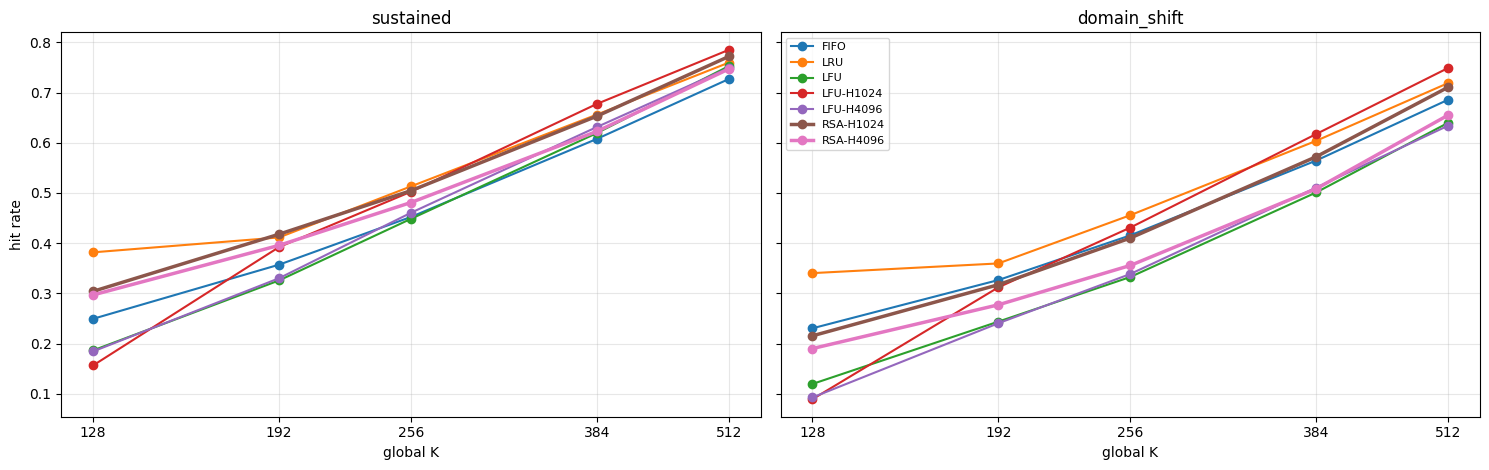

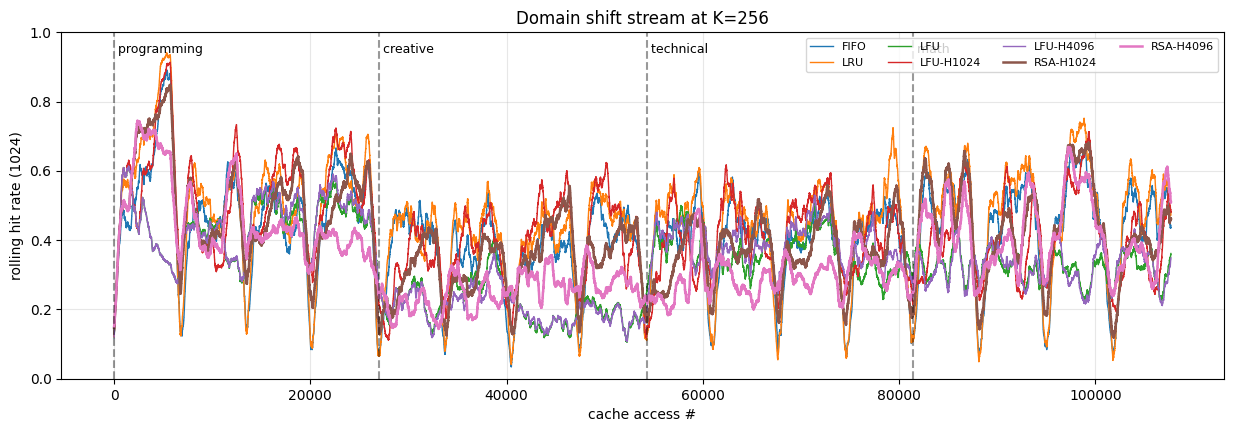

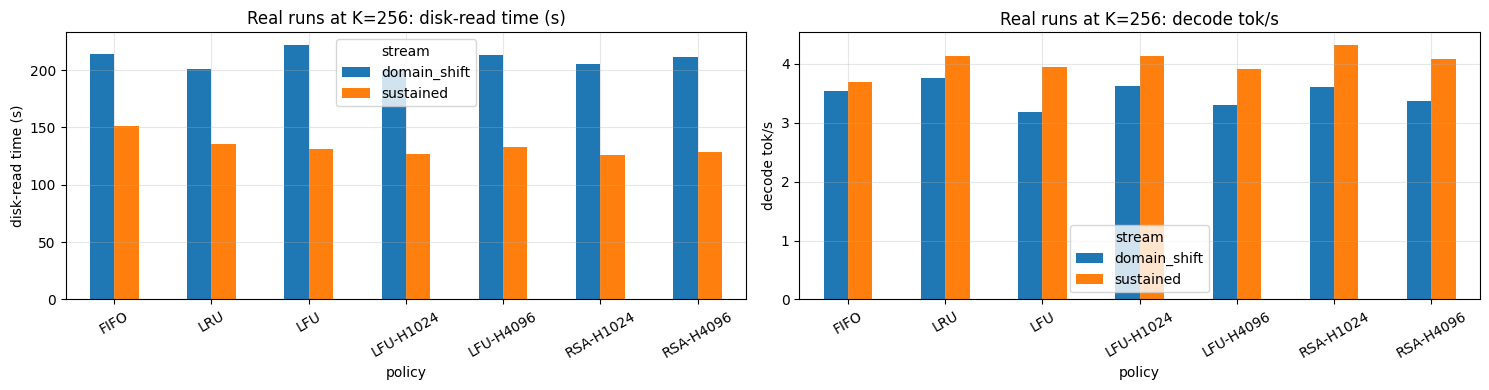

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, sname in zip(axes, traces):
    d = sweep[sweep.stream == sname]
    for i, pname in enumerate(POLICIES):
        dd = d[d.policy == pname].sort_values('K')
        ax.plot(dd.K, dd.hit_rate, '-o', label=pname, lw=2.5 if pname.startswith('RSA') else 1.5)
    ax.set_xscale('log', base=2); ax.set_xticks(sorted(d.K.unique())); ax.set_xticklabels(sorted(d.K.unique()))
    ax.set_title(sname); ax.set_xlabel('global K')
axes[0].set_ylabel('hit rate'); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS / 'axis2_hit_vs_K.png', dpi=150, bbox_inches='tight'); plt.show()

# Rolling hit rate along the domain-shift stream
acc = frames['domain_shift']
dom = acc.prompt.map(lambda i: STREAMS['domain_shift'][i]['domain']).to_numpy()
bounds = [int(np.flatnonzero(dom == d)[0]) for d in SHIFT_DOMAINS]
fig, ax = plt.subplots(figsize=(15, 4.5))
for pname in POLICIES:
    ax.plot(rolling[('domain_shift', pname)], label=pname, lw=1.8 if pname.startswith('RSA') else 1)
for b, d in zip(bounds, SHIFT_DOMAINS):
    ax.axvline(b, color='k', ls='--', alpha=0.4); ax.text(b, 0.97, f' {d}', va='top', fontsize=9)
ax.set_ylim(0, 1); ax.set_xlabel('cache access #'); ax.set_ylabel(f'rolling hit rate ({ROLLING})')
ax.set_title(f'Domain shift stream at K={REAL_K}'); ax.legend(ncol=4, fontsize=8)
fig.savefig(RESULTS / 'axis2_rolling.png', dpi=150, bbox_inches='tight'); plt.show()

# Real cost at the headline K
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, col, lab in [(axes[0], 'io_s', 'disk-read time (s)'), (axes[1], 'decode_tok_s', 'decode tok/s')]:
    p = real.pivot(index='policy', columns='stream', values=col).loc[list(POLICIES)]
    p.plot.bar(ax=ax, rot=30); ax.set_ylabel(lab); ax.set_title(f'Real runs at K={REAL_K}: {lab}')
fig.tight_layout(); fig.savefig(RESULTS / 'axis2_real_cost.png', dpi=150, bbox_inches='tight'); plt.show()

## Locality analysis
A policy can only exploit structure that exists. Three views of the access stream:
* **Frequency skew** — how concentrated accesses are (Gini; share of the top 64 experts).
* **Reuse time** — accesses since the last request for the same expert. A K-slot cache can only hit re-uses that come back "soon enough".
* **Domain overlap** — Jaccard similarity of each domain's top-256 most-used experts (what a cache of that size would hold). Low overlap is what makes stale LFU counts costly after a shift.

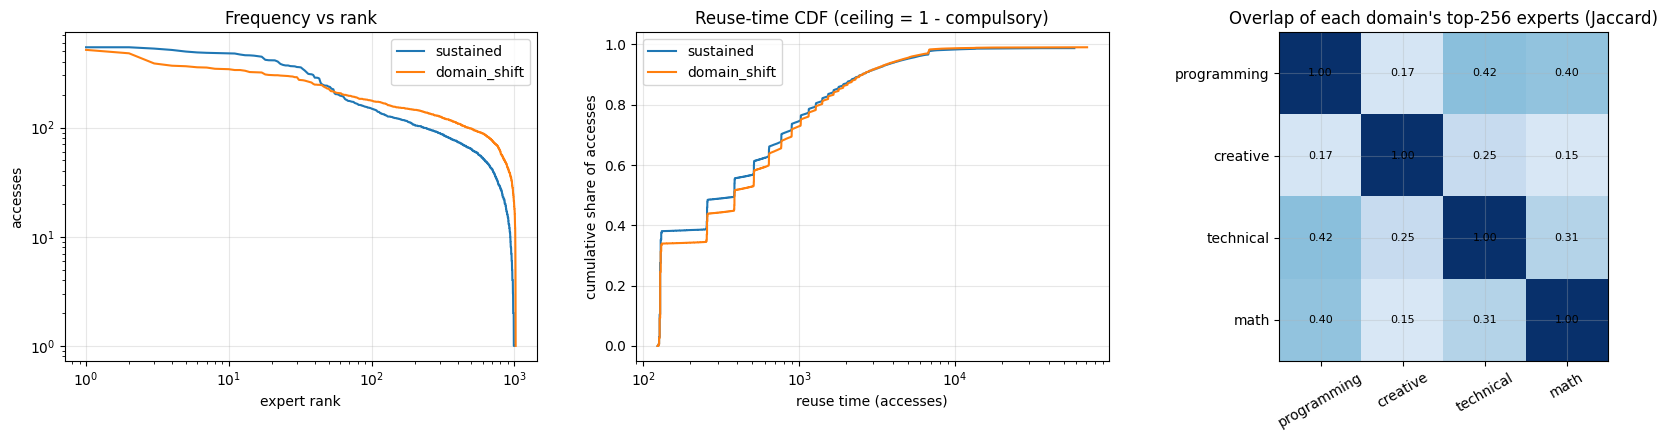

,stream,accesses,distinct,gini,top64_share,top256_share
0,sustained,81390,1000,0.45,26.9%,56.1%
1,domain_shift,108727,1022,0.31,16.5%,44.3%


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
stats = []
for sname, acc in frames.items():
    keys = list(zip(acc.layer, acc.eid))
    cnt = np.array(sorted(pd.Series(keys).value_counts().values, reverse=True))
    stats.append({'stream': sname, 'accesses': len(keys), 'distinct': len(cnt), 'gini': mc.gini(cnt),
                  'top64_share': cnt[:64].sum() / cnt.sum(), 'top256_share': cnt[:256].sum() / cnt.sum()})
    axes[0].loglog(np.arange(1, len(cnt) + 1), cnt, label=sname)
    last, reuse = {}, []
    for i, k in enumerate(keys):
        if k in last:
            reuse.append(i - last[k])
        last[k] = i
    r = np.sort(reuse)
    axes[1].plot(r, np.arange(1, len(r) + 1) / len(keys), label=sname)
axes[0].set_xlabel('expert rank'); axes[0].set_ylabel('accesses'); axes[0].set_title('Frequency vs rank'); axes[0].legend()
axes[1].set_xscale('log'); axes[1].set_xlabel('reuse time (accesses)'); axes[1].set_ylabel('cumulative share of accesses')
axes[1].set_title('Reuse-time CDF (ceiling = 1 - compulsory)'); axes[1].legend()

acc = frames['domain_shift']
acc = acc.assign(domain=acc.prompt.map(lambda i: STREAMS['domain_shift'][i]['domain']))
# Nearly every expert is touched by every domain at least once, so compare what a
# cache would actually keep: each domain's TOP_N most-used experts.
TOP_N = 256
sets = {d: set(g.groupby(['layer', 'eid']).size().nlargest(TOP_N).index) for d, g in acc.groupby('domain')}
names = [d for d in SHIFT_DOMAINS if d in sets]
jac = np.array([[len(sets[a] & sets[b]) / len(sets[a] | sets[b]) for b in names] for a in names])
im = axes[2].imshow(jac, vmin=0, vmax=1, cmap='Blues')
axes[2].set_xticks(range(len(names))); axes[2].set_xticklabels(names, rotation=30)
axes[2].set_yticks(range(len(names))); axes[2].set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)):
        axes[2].text(j, i, f'{jac[i, j]:.2f}', ha='center', va='center', fontsize=8)
axes[2].set_title(f'Overlap of each domain\'s top-{TOP_N} experts (Jaccard)')
fig.tight_layout(); fig.savefig(RESULTS / 'axis2_locality.png', dpi=150, bbox_inches='tight'); plt.show()
pd.DataFrame(stats).style.format({'gini': '{:.2f}', 'top64_share': '{:.1%}', 'top256_share': '{:.1%}'})

## Hypothesis check (descriptive)

In [10]:
def hr(stream, K, p, col='hit_rate'):
    return float(sweep[(sweep.stream == stream) & (sweep.K == K) & (sweep.policy == p)][col].iloc[0])

Ks = sorted(sweep.K.unique())
print('H1  sustained: LFU vs LRU')
for K in Ks:
    a, b = hr('sustained', K, 'LFU'), hr('sustained', K, 'LRU')
    print(f'   K={K:4d}: LFU {a:.1%} vs LRU {b:.1%}  ->  {"LFU better" if a > b else "LRU better or equal"} ({a - b:+.1%})')
print('\nH2  domain shift: un-decayed LFU vs LRU (overall | post-shift window)')
for K in Ks:
    a, b = hr('domain_shift', K, 'LFU'), hr('domain_shift', K, 'LRU')
    pa, pb = hr('domain_shift', K, 'LFU', 'post_shift'), hr('domain_shift', K, 'LRU', 'post_shift')
    print(f'   K={K:4d}: {a:.1%} vs {b:.1%} | post-shift {pa:.1%} vs {pb:.1%}  ->  '
          f'{"supports H2" if (a < b and pa < pb) else "does not support H2"}')
print('\nRouter-score-aware policy: rank among all policies (1 = best hit rate)')
for sname in traces:
    for K in Ks:
        d = sweep[(sweep.stream == sname) & (sweep.K == K)].set_index('policy').hit_rate.sort_values(ascending=False)
        rsa = [p for p in d.index if p.startswith('RSA')]
        best_rsa = max(rsa, key=lambda p: d[p])
        print(f'   {sname:13s} K={K:4d}: best RSA = {best_rsa} rank {list(d.index).index(best_rsa) + 1}/{len(d)} '
              f'({d[best_rsa]:.1%} vs best {d.index[0]} {d.iloc[0]:.1%})')
print('\nTreat differences of about a point as noise: one fixed prompt set, one seed.')

H1  sustained: LFU vs LRU
   K= 128: LFU 18.6% vs LRU 38.2%  ->  LRU better or equal (-19.5%)
   K= 192: LFU 32.6% vs LRU 41.1%  ->  LRU better or equal (-8.6%)
   K= 256: LFU 44.9% vs LRU 51.3%  ->  LRU better or equal (-6.5%)
   K= 384: LFU 61.9% vs LRU 65.6%  ->  LRU better or equal (-3.7%)
   K= 512: LFU 75.3% vs LRU 76.0%  ->  LRU better or equal (-0.7%)

H2  domain shift: un-decayed LFU vs LRU (overall | post-shift window)
   K= 128: 11.9% vs 34.0% | post-shift 8.9% vs 29.9%  ->  supports H2
   K= 192: 24.4% vs 36.0% | post-shift 20.9% vs 31.1%  ->  supports H2
   K= 256: 33.3% vs 45.6% | post-shift 31.2% vs 45.1%  ->  supports H2
   K= 384: 50.1% vs 60.4% | post-shift 48.5% vs 59.5%  ->  supports H2
   K= 512: 64.0% vs 71.9% | post-shift 61.9% vs 71.5%  ->  supports H2

Router-score-aware policy: rank among all policies (1 = best hit rate)
   sustained     K= 128: best RSA = RSA-H1024 rank 2/7 (30.4% vs best LRU 38.2%)
   sustained     K= 192: best RSA = RSA-H1024 rank 1/7 (41.8